In [1]:
import torch
import matplotlib.pyplot as plt

from ml.layers import SoftHistogramLayer
from ml.models import HistNetwork, DeepSetNetwork
from ml.utils import get_model_size, count_trainable_parameters

torch.manual_seed(42);

In [49]:
t = torch.rand((3, 400)) * 100
#t = torch.normal(mean=torch.ones(2, 400)+100, std=torch.zeros(2, 400) + 20)

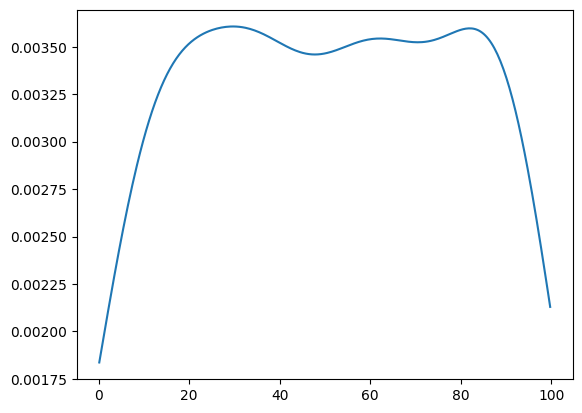

In [53]:
shist = SoftHistogramLayer(num_bins=300, max_val=t.max().item(), init_sigma=10.1, normalize=True)

densities = shist(t)[0].detach().numpy()
bin_centers = shist.bin_centers.detach().numpy()


plt.plot(bin_centers, densities);

In [3]:
hist = HistNetwork(num_bins=700, taumax=100)
deepset = DeepSetNetwork(input_dim=1, hidden_dims_phi=[128, 128, 128], hidden_dims_rho=[64, 32, 16], output_dim=1)

models = [hist, deepset]

for model in models:
    print(f"Total trainable parameters for {type(model).__name__}: {count_trainable_parameters(model):,}")


# for model in models:
#     print(f"\n{type(model).__name__} model architecture:\n{model}")

for model in models:
    size_in_mb = get_model_size(model)
    print(f'{type(model).__name__} model size: {size_in_mb} MB')


Total trainable parameters for HistNetwork: 77,412
Total trainable parameters for DeepSetNetwork: 60,673
HistNetwork model size: 0.2953033447265625 MB
DeepSetNetwork model size: 0.23144912719726562 MB
